In [1]:
# Colab / fresh environment: install the module (builds the C++ core, takes a few minutes the first time)
try:
    import sensor_fusion
except ImportError:
    %pip install -q git+https://github.com/Rudip1/learn-sensor-fusion

# 8 · Dynamic objects: ground removal, clustering, temporal consistency

**Recap** ([theory](../../1_theory/08_dynamic_objects.md)). RANSAC finds the ground plane among points within $\tau$
of it (8.1), with planes far from horizontal rejected (Algorithm 8.1). DBSCAN groups the rest through
$\varepsilon$-neighbourhoods (8.2) of core points (Algorithm 8.2). A cluster is dynamic when its voxels are occupied in
few of the scans of a window: persistence (8.3) below a threshold (8.4).

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sensor_fusion import objects, scenarios as sc
from sensor_fusion.plotting import SERIES, use_style

use_style()
rng = np.random.default_rng(8)
drive = sc.dynamic_drive(0.0)                      # ego vehicle standing at x = -10 m, 30 scans in 3 s
scan = drive[15]
p, lab_true = scan["points"], scan["labels"]
print(f"{len(drive)} scans; scan 15: {len(p)} points, {np.mean(lab_true == -1):.0%} ground, "
      f"{np.sum(np.isin(lab_true, sc.MOVER_IDS))} on the moving car and pedestrian")

30 scans; scan 15: 9474 points, 25% ground, 60 on the moving car and pedestrian


### ✏️ Exercise 1 — RANSAC ground plane
Implement `ransac_ground(points, tau, iterations, max_tilt_deg)` returning `(normal, d, inlier mask)` with
Algorithm 8.1 (without the final refit). Compare the inliers with `objects.segment_ground`.

In [3]:
def ransac_ground(points, tau=0.15, iterations=500, max_tilt_deg=15.0, rng=rng):
    ### BEGIN SOLUTION
    best, best_count = None, -1
    for _ in range(iterations):
        a, b, c = points[rng.choice(len(points), 3, replace=False)]
        n = np.cross(b - a, c - a)
        if np.linalg.norm(n) < 1e-9:
            continue
        n /= np.linalg.norm(n)
        n *= np.sign(n[2]) or 1.0
        if np.degrees(np.arccos(min(1.0, n[2]))) > max_tilt_deg:
            continue
        d = -n @ a
        count = np.sum(np.abs(points @ n + d) < tau)
        if count > best_count:
            best, best_count = (n, d), count
    n, d = best
    return n, d, np.abs(points @ n + d) < tau
    ### END SOLUTION

In [4]:
n, d, g = ransac_ground(p)
ref = np.array(objects.segment_ground(p)["ground"])
truth = lab_true == -1
print(f"normal {np.round(n, 3)}, d = {d:.2f}; agreement with segment_ground {np.mean(g == ref):.3f}; correct {np.mean(g == truth):.3f}")
assert np.mean(g == ref) > 0.99 and abs(d - 1.8) < 0.05
print("✅ ransac_ground")

normal [-0. -0.  1.], d = 1.80; agreement with segment_ground 0.999; correct 0.984
✅ ransac_ground


### ✏️ Exercise 2 — DBSCAN
Implement `my_dbscan(points, eps, min_points)` for small point sets with the definitions of section 8.3
(brute-force neighbourhoods are fine). Compare the partition with `objects.dbscan` on the non-ground points of
the scan near the pedestrian.

In [5]:
def my_dbscan(points, eps, min_points):
    ### BEGIN SOLUTION
    n = len(points)
    D = np.linalg.norm(points[:, None] - points[None], axis=2)
    nb = [np.flatnonzero(D[i] <= eps) for i in range(n)]
    core = np.array([len(x) >= min_points for x in nb])
    label = np.full(n, -1)
    c = 0
    for i in range(n):
        if label[i] >= 0 or not core[i]:
            continue
        label[i] = c
        queue = [i]
        while queue:
            j = queue.pop()
            if not core[j]:
                continue
            for q in nb[j]:
                if label[q] < 0:
                    label[q] = c
                    queue.append(q)
        c += 1
    return label
    ### END SOLUTION

In [6]:
ng = p[~ref]
near = ng[np.linalg.norm(ng[:, :2] - (np.array([8.0, -2.2]) - [-10.0, 0.0]), axis=1) < 6]   # around the pedestrian
a, b = my_dbscan(near, 0.5, 3), np.array(objects.dbscan(near, 0.5, 3))
pairs = {(x, y) for x, y in zip(a, b)}
assert all((x < 0) == (y < 0) for x, y in pairs) and len({x for x, _ in pairs}) == len({y for _, y in pairs})
print(f"✅ my_dbscan: same partition, {a.max() + 1} clusters among {len(near)} points")

✅ my_dbscan: same partition, 7 clusters among 91 points


### ✏️ Exercise 3 — persistence
Implement eq. (8.3): for every point of every world-frame scan, the fraction of scans that have a point in its
voxel. Compare with `objects.persistence`.

In [7]:
def my_persistence(world_scans, voxel):
    ### BEGIN SOLUTION
    from collections import Counter
    keys = [np.floor(w / voxel).astype(int) for w in world_scans]
    occ = Counter()
    for k in keys:
        occ.update(set(map(tuple, k)))
    return [np.array([occ[tuple(x)] for x in k]) / len(world_scans) for k in keys]
    ### END SOLUTION

In [8]:
world = [s["points"] @ s["T_world_sensor"][:3, :3].T + s["T_world_sensor"][:3, 3] for s in drive]
mine = my_persistence(world, 0.5)
ref = objects.persistence(world, 0.5)
assert all(np.allclose(a, b) for a, b in zip(mine, ref))
movers = np.concatenate([np.isin(s["labels"], sc.MOVER_IDS) for s in drive])
ground = np.concatenate([s["labels"] == -1 for s in drive])
pers = np.concatenate(mine)
print(f"✅ my_persistence. Median: static objects {np.median(pers[~movers & ~ground]):.2f}, movers {np.median(pers[movers]):.2f}")

✅ my_persistence. Median: static objects 0.93, movers 0.03


## 1. The whole pipeline

ego standing: precision 0.99, recall 0.72


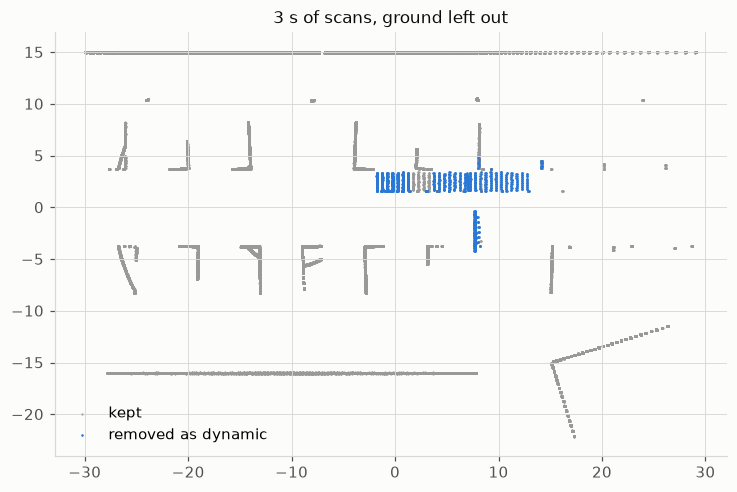

In [9]:
def pipeline(drive, eps=0.5, min_points=3, voxel=0.5, ratio=0.3):
    world, labels = [], []
    for k, s in enumerate(drive):
        pts, T = s["points"], s["T_world_sensor"]
        g = np.array(objects.segment_ground(pts, 0.15, 500, 15.0, k)["ground"])
        lab = np.full(len(pts), -1)
        lab[~g] = objects.dbscan(pts[~g], eps, min_points)
        world.append(pts @ T[:3, :3].T + T[:3, 3])
        labels.append(lab)
    dyn = np.concatenate(objects.dynamic_points(world, [l.tolist() for l in labels], voxel, ratio))
    mov = np.concatenate([np.isin(s["labels"], sc.MOVER_IDS) for s in drive])
    tp = np.sum(dyn & mov)
    return round(float(tp / max(dyn.sum(), 1)), 2), round(float(tp / mov.sum()), 2), np.concatenate(world), dyn


prec, rec, W, dyn = pipeline(drive)
print(f"ego standing: precision {prec}, recall {rec}")
keep = np.concatenate([s["labels"] != -1 for s in drive])
plt.figure(figsize=(9, 5))
plt.scatter(W[keep & ~dyn, 0], W[keep & ~dyn, 1], s=0.2, color="0.6", label="kept")
plt.scatter(W[dyn, 0], W[dyn, 1], s=0.5, color=SERIES[0], label="removed as dynamic")
plt.gca().set_aspect("equal"); plt.legend(); plt.title("3 s of scans, ground left out"); plt.show()

## 🔨 Break it — a height threshold on a pitched sensor

In [10]:
for pitch in (0.0, 3.0):
    s = sc.dynamic_drive(0.0, 0.1, pitch_deg=pitch)[0]
    t = s["labels"] == -1
    h = np.array(objects.ground_by_height(s["points"], -1.8 + 0.15))
    r = np.array(objects.segment_ground(s["points"])["ground"])
    print(f"pitch {pitch} deg: height threshold {np.mean(h == t):.3f} correct, RANSAC {np.mean(r == t):.3f}")

pitch 0.0 deg: height threshold 0.983 correct, RANSAC 0.983
pitch 3.0 deg: height threshold 0.836 correct, RANSAC 0.975


## 🔨 Break it — the wrong ε

In [11]:
for eps, mp in ((0.5, 3), (0.6, 5), (1.0, 3)):
    noise_ped = 0; merged = 0
    for k, s in enumerate(drive):
        g = np.array(objects.segment_ground(s["points"], 0.15, 500, 15.0, k)["ground"])
        lab = np.full(len(g), -1); lab[~g] = objects.dbscan(s["points"][~g], eps, mp)
        ped = (s["labels"] == 101) & ~g
        noise_ped += np.sum(ped & (lab < 0))
        car_clusters = set(lab[(s["labels"] == 100) & (lab >= 0)])
        merged += sum(np.any(np.isin(s["labels"][lab == c], [l for l in range(1, 100)])) for c in car_clusters)
    total_ped = sum(np.sum(s["labels"] == 101) for s in drive)
    print(f"eps {eps}, min {mp}: {noise_ped} of {total_ped} pedestrian points are noise; car merged with parked cars in {merged} scans; "
          f"(precision, recall) = {pipeline(drive, eps, mp)[:2]}")

eps 0.5, min 3: 3 of 381 pedestrian points are noise; car merged with parked cars in 9 scans; (precision, recall) = (0.99, 0.72)


eps 0.6, min 5: 276 of 381 pedestrian points are noise; car merged with parked cars in 12 scans; (precision, recall) = (0.98, 0.53)


eps 1.0, min 3: 0 of 381 pedestrian points are noise; car merged with parked cars in 14 scans; (precision, recall) = (1.0, 0.57)


## 🔨 Break it — a moving ego vehicle

In [12]:
prec, rec, _, _ = pipeline(sc.dynamic_drive(2.0))
print(f"ego at 2 m/s: precision {prec}, recall {rec}  (static surfaces coming into view look non-persistent)")

ego at 2 m/s: precision 0.63, recall 0.8  (static surfaces coming into view look non-persistent)


## What to remember

- Fit the ground (RANSAC with a tilt limit); do not threshold the height.
- DBSCAN's ε must bridge the gaps between rings at the ranges you care about, but not the gaps between objects.
- Persistence separates static from moving — per object, over a window long enough for the motion.
- Persistence cannot tell "not seen" from "not there"; with ego motion, free-space reasoning is needed.